In [ ]:
#  python -m venv myenv
# myenv\Scripts\activate

# pip install virtualenv
#  virtualenv -p python3 virtual_env

# conda create -p venv python==3.10 -y

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error


df = pd.read_csv("uber.csv")
print(df.head())
print(df.info())


# Remove unnecessary columns
df.drop(['Unnamed: 0', 'key'], axis=1, inplace=True, errors='ignore')
# Remove missing values
df.dropna(inplace=True)
# Remove invalid values
# df = df[(df['fare_amount'] > 0) &
#         (df['passenger_count'] > 0)]
# # Remove invalid coordinates
# df = df[df['pickup_longitude'].between(-75, -72)]
# df = df[df['dropoff_longitude'].between(-75, -72)]
# df = df[df['pickup_latitude'].between(40, 42)]
# df = df[df['dropoff_latitude'].between(40, 42)]
print(df.head())
print("Shape:", df.shape)


sns.boxplot(x=df['fare_amount'])
plt.title("Fare Amount Outliers")
plt.show()
# Remove outliers using IQR
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)
IQR = Q3 - Q1
df = df[(df['fare_amount'] >= Q1 - 1.5*IQR) &
        (df['fare_amount'] <= Q3 + 1.5*IQR)]



plt.figure(figsize=(8, 5))
sns.heatmap(df.select_dtypes(include=np.number).corr(),
            annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()



X = df[['pickup_longitude', 'pickup_latitude',
        'dropoff_longitude', 'dropoff_latitude',
        'passenger_count']]
y = df['fare_amount']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)



lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred1 = lr.predict(X_test)
print("Linear Regression R2:", r2_score(y_test, y_pred1))
print("Linear Regression RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred1)))



rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(X_train, y_train)
y_pred2 = rf.predict(X_test)
print("Random Forest R2:", r2_score(y_test, y_pred2))
print("Random Forest RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred2)))



results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [
        r2_score(y_test, y_pred1),
        r2_score(y_test, y_pred2)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred1)),
        np.sqrt(mean_squared_error(y_test, y_pred2))
    ]
})
print(results)



sample = [[-73.99, 40.73, -73.98, 40.75, 1]]
fare = rf.predict(sample)
print("Predicted Uber Fare:", fare[0])

In [2]:
df = pd.read_csv("uber.csv")

print(df.head())
print(df.info())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [ ]:
# Remove unnecessary columns
df.drop(['Unnamed: 0', 'key'], axis=1, inplace=True, errors='ignore')

# Remove missing values
df.dropna(inplace=True)

# # Remove invalid values
# df = df[(df['fare_amount'] > 0) &
#         (df['passenger_count'] > 0)]

# # Remove invalid coordinates
# df = df[df['pickup_longitude'].between(-75, -72)]
# df = df[df['dropoff_longitude'].between(-75, -72)]
# df = df[df['pickup_latitude'].between(40, 42)]
# df = df[df['dropoff_latitude'].between(40, 42)]

print(df.head())
print("Shape:", df.shape)

   fare_amount          pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1          7.7  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2         12.9  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3          5.3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4         16.0  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         -73.965316         40.803349                3  
4         -73.973082         40.761247                5  
Shape: (178393, 7)


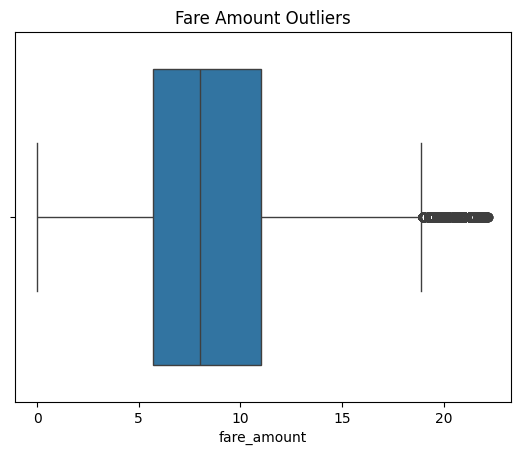

In [13]:
sns.boxplot(x=df['fare_amount'])
plt.title("Fare Amount Outliers")
plt.show()

# Remove outliers using IQR
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

df = df[(df['fare_amount'] >= Q1 - 1.5*IQR) &
        (df['fare_amount'] <= Q3 + 1.5*IQR)]

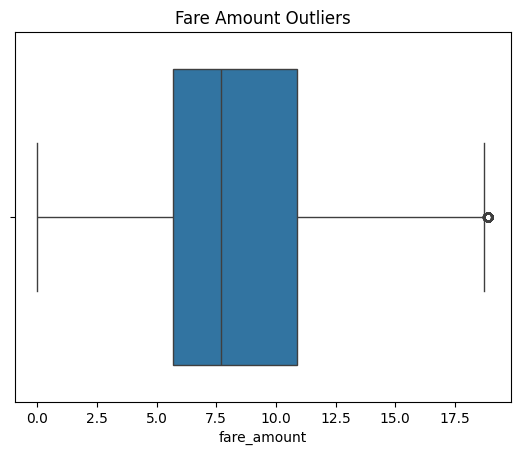

In [14]:
sns.boxplot(x=df['fare_amount'])
plt.title("Fare Amount Outliers")
plt.show()

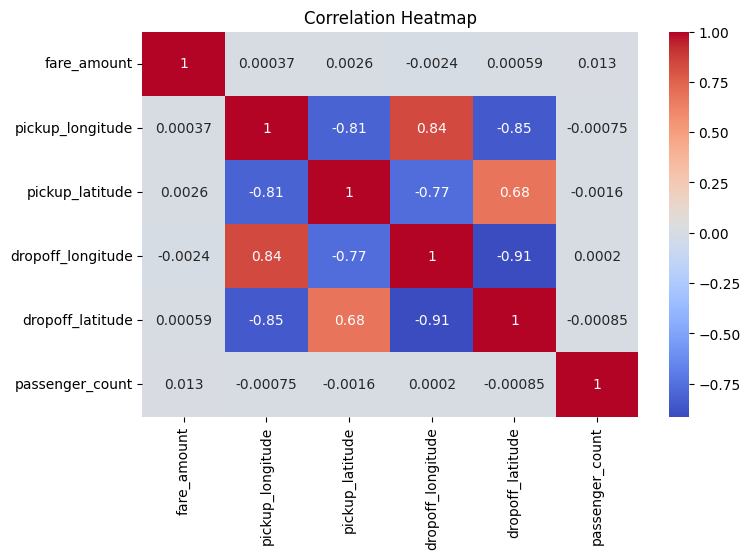

In [5]:
plt.figure(figsize=(8, 5))
sns.heatmap(df.select_dtypes(include=np.number).corr(),
            annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

In [6]:
X = df[['pickup_longitude', 'pickup_latitude',
        'dropoff_longitude', 'dropoff_latitude',
        'passenger_count']]

y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [7]:
lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred1 = lr.predict(X_test)

print("Linear Regression R2:", r2_score(y_test, y_pred1))
print("Linear Regression RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred1)))

Linear Regression R2: 8.29713376748753e-05
Linear Regression RMSE: 4.136624287486402


In [8]:
rf = RandomForestRegressor(n_estimators=50, random_state=42)

rf.fit(X_train, y_train)

y_pred2 = rf.predict(X_test)

print("Random Forest R2:", r2_score(y_test, y_pred2))
print("Random Forest RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred2)))

Random Forest R2: 0.7022370012127884
Random Forest RMSE: 2.2573529045563627


In [9]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [
        r2_score(y_test, y_pred1),
        r2_score(y_test, y_pred2)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred1)),
        np.sqrt(mean_squared_error(y_test, y_pred2))
    ]
})

print(results)

               Model  R2 Score      RMSE
0  Linear Regression  0.000083  4.136624
1      Random Forest  0.702237  2.257353


In [10]:
sample = [[-73.99, 40.73, -73.98, 40.75, 1]]

fare = rf.predict(sample)

print("Predicted Uber Fare:", fare[0])

Predicted Uber Fare: 8.244


C:\Users\Susha\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
